##  House Price Prediction in Python - Full ML Project

1. Exploring dataset
2. Preprocessing data
3. Engineer some features
4. Training and Evaluating ML Models

Requirements:
- We need iPython Notebook environment (Jupyter Notebook, Google Coolab, ...)
- installation of the basic datascience libraries (e.g., pandas, numpy, matplotlib, seaborn, scikit-learn), you can install these libraries using the command: ```pip install pandas numpy matplotlib seaborn scikit-learn ```


### Dataset: California Housing Prices
The data pertains to the houses found in a given California district and some summary stats about them based on the 1990 census data.

Note, The data isn't cleaned so there are some preprocessing steps required!

The columns are as follows, their names are pretty self explanitory:

longitude

latitude

housing_median_age

total_rooms

total_bedrooms

population

households

median_income

**median_house_value**

ocean_proximity

We are going to use the "**median_house_value**" as the target label (This is what we want to predict). We use the other features (columns) in the dataset (e.g., house_median_age, total_rooms, ...) to predict the house values.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix


%matplotlib inline

In [ ]:
df = pd.read_csv('housing.csv', sep=',', encoding ='utf8')

### Data Exploration
Exploratory Data Analysis (EDA): Helps you understand how categorical data is distributed (which categories are most or least common).

Get the head, tail and some random samples from the dataset

In [ ]:
df.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df.tail(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [ ]:
df.sample(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
16056,-122.49,37.76,52.0,2564.0,502.0,1092.0,459.0,3.5302,329600.0,NEAR BAY
10327,-117.77,33.85,13.0,5415.0,827.0,2061.0,714.0,7.3681,353100.0,<1H OCEAN
16141,-122.46,37.78,52.0,3088.0,727.0,1636.0,662.0,2.8553,360700.0,NEAR BAY
1888,-119.98,38.92,28.0,1408.0,312.0,522.0,221.0,2.0708,89600.0,INLAND
2417,-119.44,36.59,28.0,1343.0,330.0,1331.0,305.0,1.5160,56700.0,INLAND


#### Data Info and Description

Let's start with the data exploration, using ```.info()``` and ```.descripe()```

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


#### Data Histogramming
We will use this technique to summarize and visualize the distribution of a dataset. It involves dividing the data into a set of intervals (called bins) and counting how many data points fall into each bin.

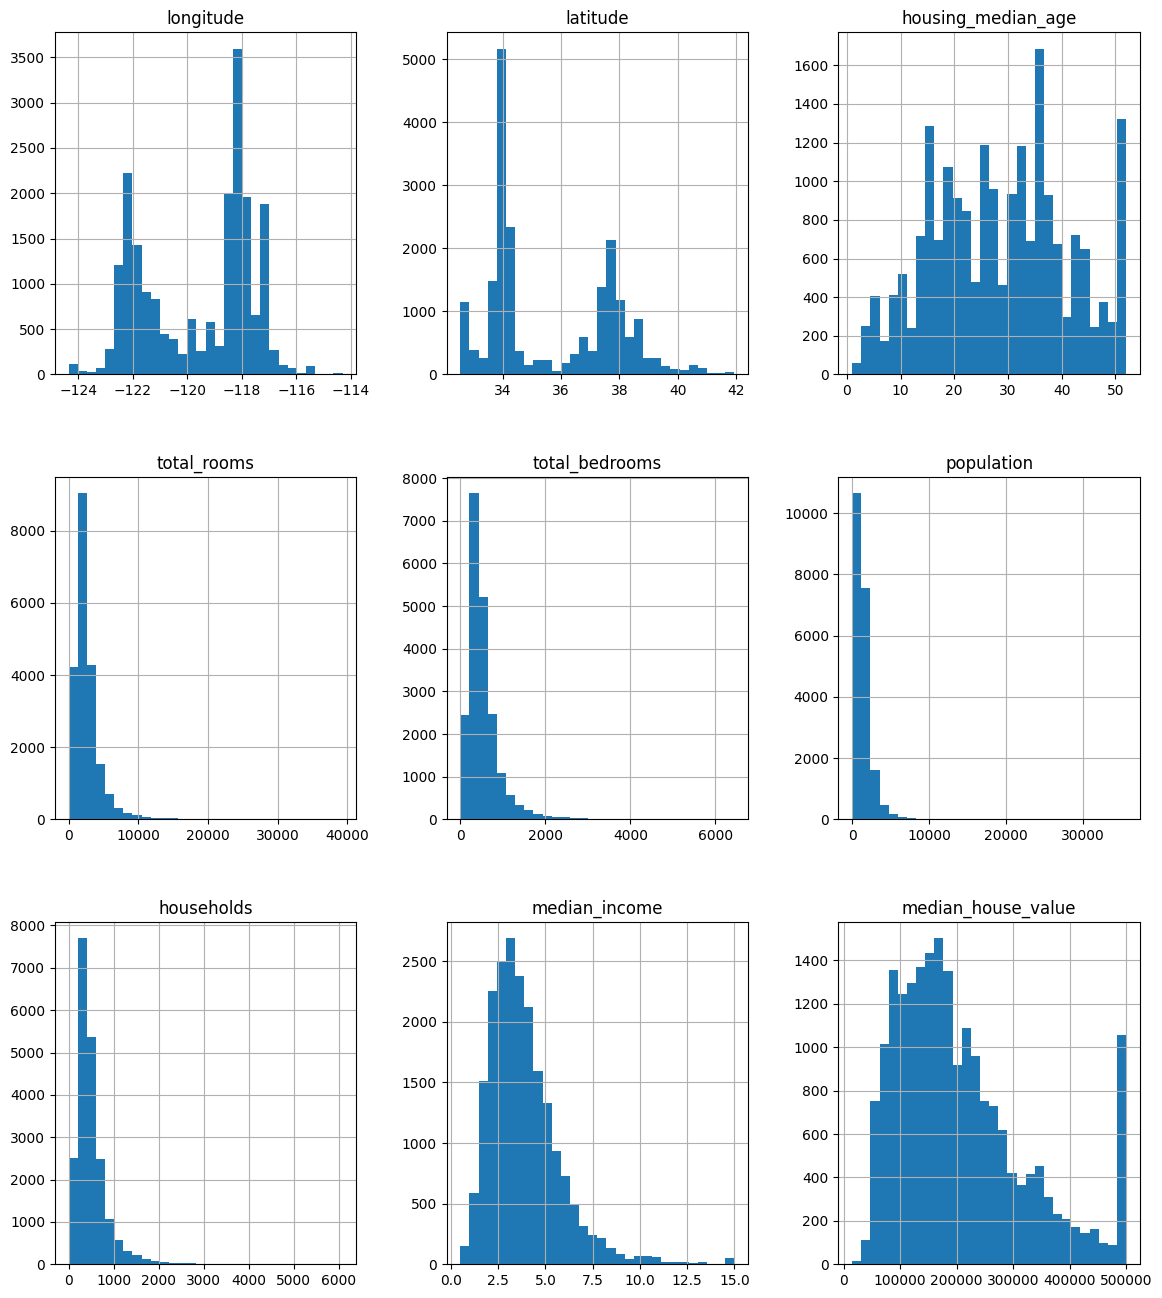

In [ ]:
df.hist(bins=30, figsize=(14,16))
plt.show()

We can do this for a single features (column)

<Axes: >

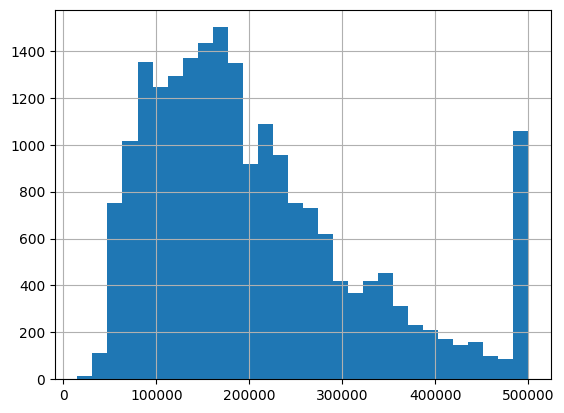

In [ ]:
df['median_house_value'].hist(bins=30)
...

##### Counting unique Values
The ```value_counts()``` function returns the frequency distribution of unique values in a specified column of a DataFrame.

For example, if we are asking “**How many times each unique value appears in the column ocean_proximity of my Dataset?**”

In [ ]:
df['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [ ]:
# Do the same for other attributes
...

## Data Preprocessing

### Missing Values

In [ ]:
df.isna().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


If You have enough samples in your dataset, it is recommended to drop these samples with nulls

In [ ]:
df.dropna(inplace=True)

Let's now check the data set information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [ ]:
df.isna().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Note, if you want to apply that and you dataset is complete, you might want to delete some random value from the dataframe and do the dropping, or maybe imputation

#### One-Hot Encoding

**One-Hot Encoding** is a way to convert categorical data into a **binary numeric format** that machine learning models can use.  

Each category becomes a **new column**, and for a given data point, the column corresponding to its category is marked as **1**, while all others are **0**.

Example:

Original Categories and Counts within ocean_promximity are as follows:

ocean_proximity
- <1H OCEAN 9034
- INLAND 6496
- NEAR OCEAN 2628
- NEAR BAY 2270
- ISLAND 5

### One-Hot Encoded Table

| ocean_proximity | <1H OCEAN | INLAND | NEAR OCEAN | NEAR BAY | ISLAND |
|-----------------|-----------|--------|------------|----------|--------|
| <1H OCEAN       | 1         | 0      | 0          | 0        | 0      |
| INLAND          | 0         | 1      | 0          | 0        | 0      |
| NEAR OCEAN      | 0         | 0      | 1          | 0        | 0      |
| NEAR BAY        | 0         | 0      | 0          | 1        | 0      |
| ISLAND          | 0         | 0      | 0          | 0        | 1      |



In [ ]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [ ]:
#To see what categories are within the feature
df.ocean_proximity.value_counts()

,count
ocean_proximity,
<1H OCEAN,9034
INLAND,6496
NEAR OCEAN,2628
NEAR BAY,2270
ISLAND,5


In [ ]:
pd.get_dummies(df.ocean_proximity)

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,False,False,False,True,False
1,False,False,False,True,False
2,False,False,False,True,False
3,False,False,False,True,False
4,False,False,False,True,False
...,...,...,...,...,...
20635,False,True,False,False,False
20636,False,True,False,False,False
20637,False,True,False,False,False
20638,False,True,False,False,False


Now, we want to join those new features to the our dataframe

- Notice that we drop the 'ocean_proximity' on the fly here

In [ ]:
df = df.join(pd.get_dummies (df.ocean_proximity)).drop(['ocean_proximity'], axis=1)

In [ ]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,False,True,False,False,False
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,False,True,False,False,False
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,False,True,False,False,False
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,False,True,False,False,False


#### Outliers

##### Way1: Checking the outliers using the box blots

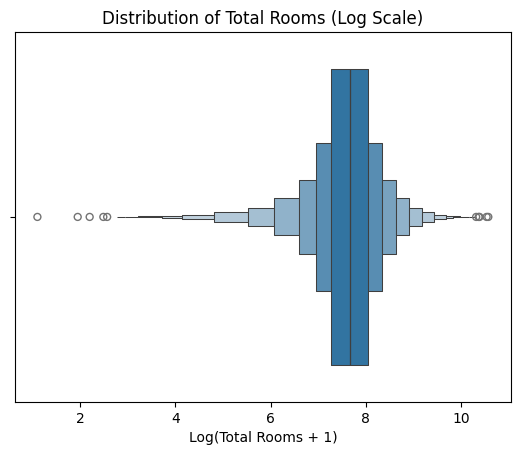

In [ ]:
sns.boxenplot(x=np.log1p(df['total_rooms']))  # log1p handles zero safely
plt.xlabel('Log(Total Rooms + 1)')
plt.title('Distribution of Total Rooms (Log Scale)')
plt.show()

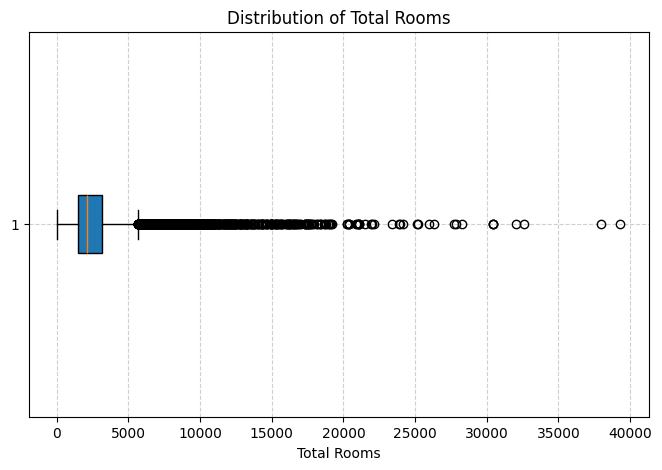

In [ ]:
import matplotlib.pyplot as plt

# Assuming df is your DataFrame
data = df['total_rooms']

plt.figure(figsize=(8, 5))
plt.boxplot(data, vert=False, patch_artist=True)

plt.xlabel('Total Rooms')
plt.title('Distribution of Total Rooms')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
print("All:", df['total_rooms'].count())

print("outliers:", df[ (df['total_rooms'] >=5000)]["total_rooms"].count())

All: 20433
outliers: 1740


Again, if you have enough data, for some ML models, it's recommended to drop the outliers

- If you decided to drop the outliers, you can apply something like this.

In [ ]:
clean_df = df [ (df ["total_rooms"] <5000 )]
clean_df.count()

,0
longitude,18693
latitude,18693
housing_median_age,18693
total_rooms,18693
total_bedrooms,18693
population,18693
households,18693
median_income,18693
median_house_value,18693
<1H OCEAN,18693


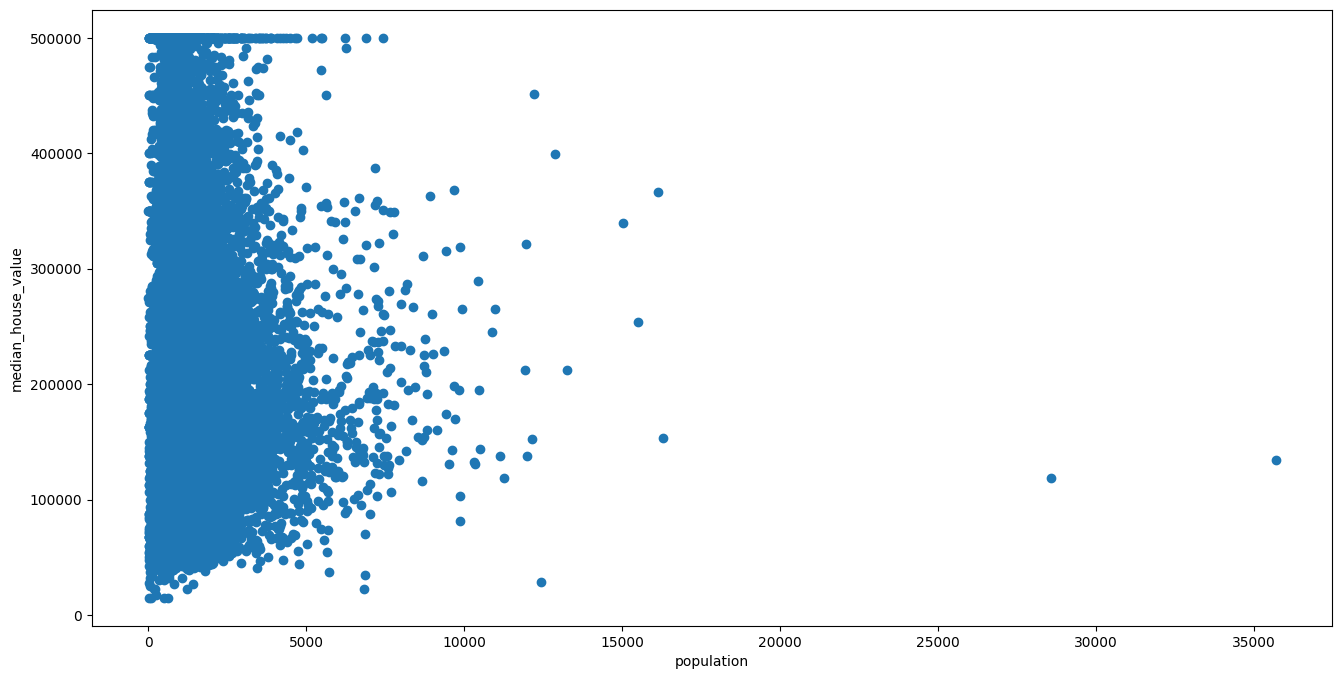

In [ ]:
fig, ax = plt.subplots(figsize=(16,8))
ax.scatter(df['population'], df['median_house_value'])

ax.set_xlabel("population")
ax.set_ylabel("median_house_value")

plt.show()

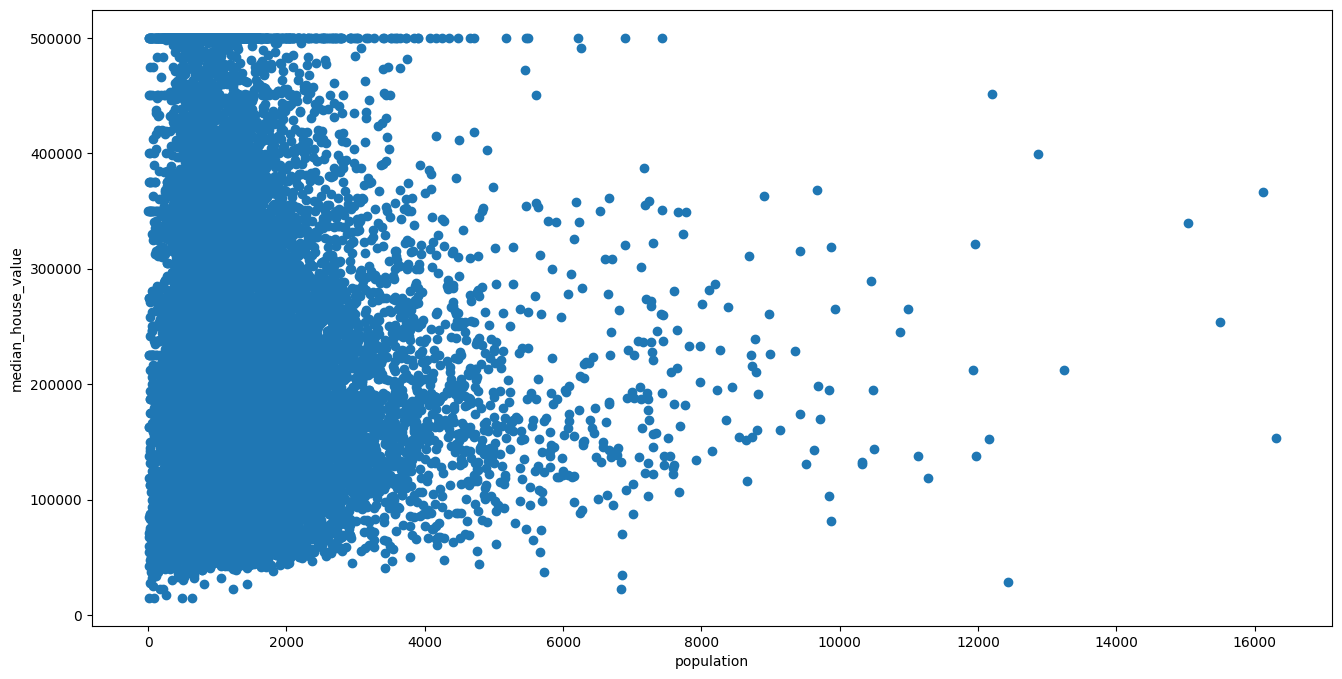

In [ ]:
t_df= df[(df['population']<20000)]

fig, ax = plt.subplots(figsize=(16,8))
ax.scatter(t_df['population'], t_df['median_house_value'])

ax.set_xlabel("population")
ax.set_ylabel("median_house_value")

plt.show()

In [ ]:
clean_df = df [ (df["total_rooms"]<5000) & (df["population"]<20000) ]

## Correlation
If you want to think, what features I might keep, and which ones you want to drop, one of the techniques is checking how correlated the features to the target label

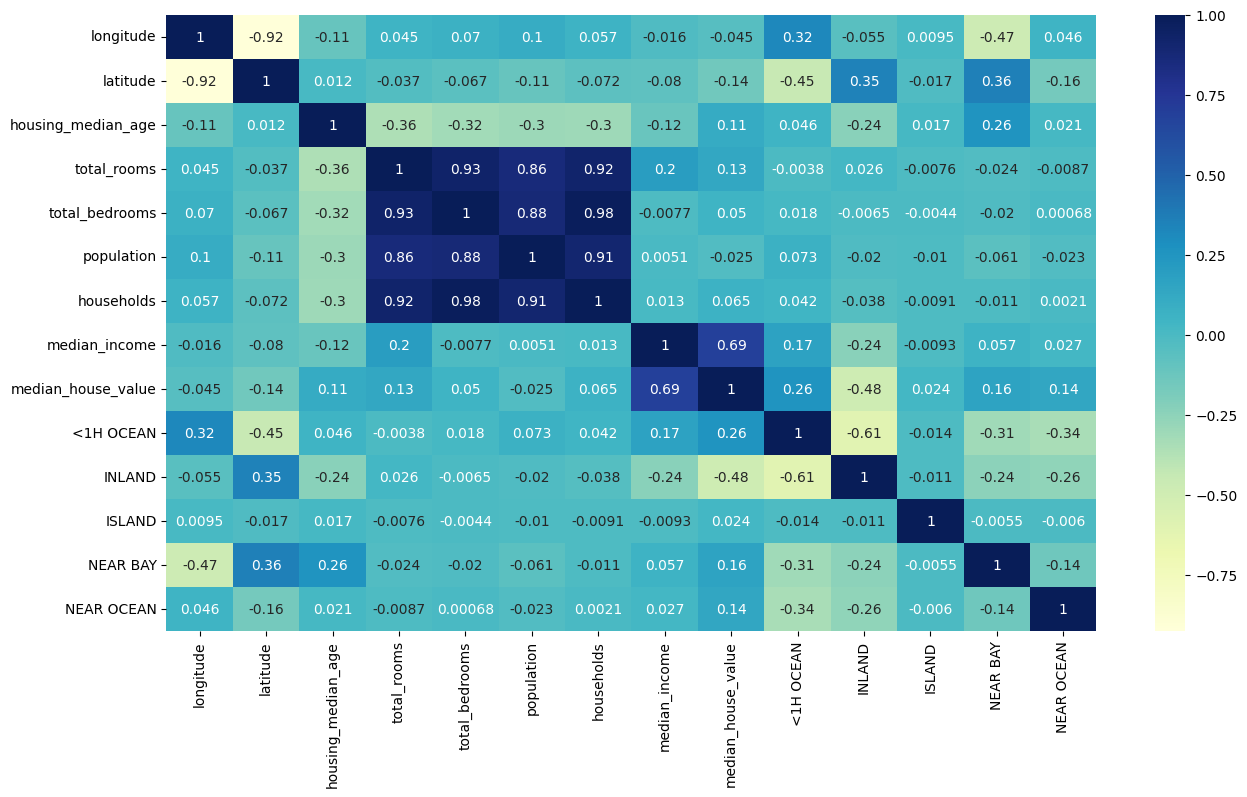

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="YlGnBu"
)
plt.show()

From this correlation, we can get how correlated the features to the target label (e.g., median_house_value). For example, we can see that the ```median_income``` feature has high positive correlation with the ```median_house_value```, so it can be a good predictor for the target variable.

Also, we can see that the ```median_house_value``` has negative correlation value with the IN_LAND.

#### Visualize Geographical Data with house values
If we put draw the house locations along with their prices, we can see intresting relationship, the closer the house to the ocean the more expensive it gets.

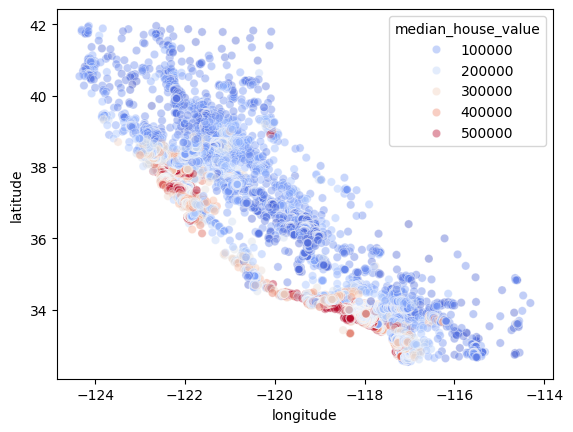

In [ ]:
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='median_house_value',
    palette='coolwarm',
    alpha=0.4
)
plt.show()

# Feature Engineering

Examples on Feature Engineering

In [ ]:
# Create a new column 'bedroom_ratio' as the ratio of bedrooms to total rooms
df ["bedroom_ratio"] = df ["total_bedrooms"]/df["total_rooms"]

# Create a new column 'household_rooms' as the average number of rooms per household
df["household_rooms"] = df ["total_rooms"]/df ["households"]

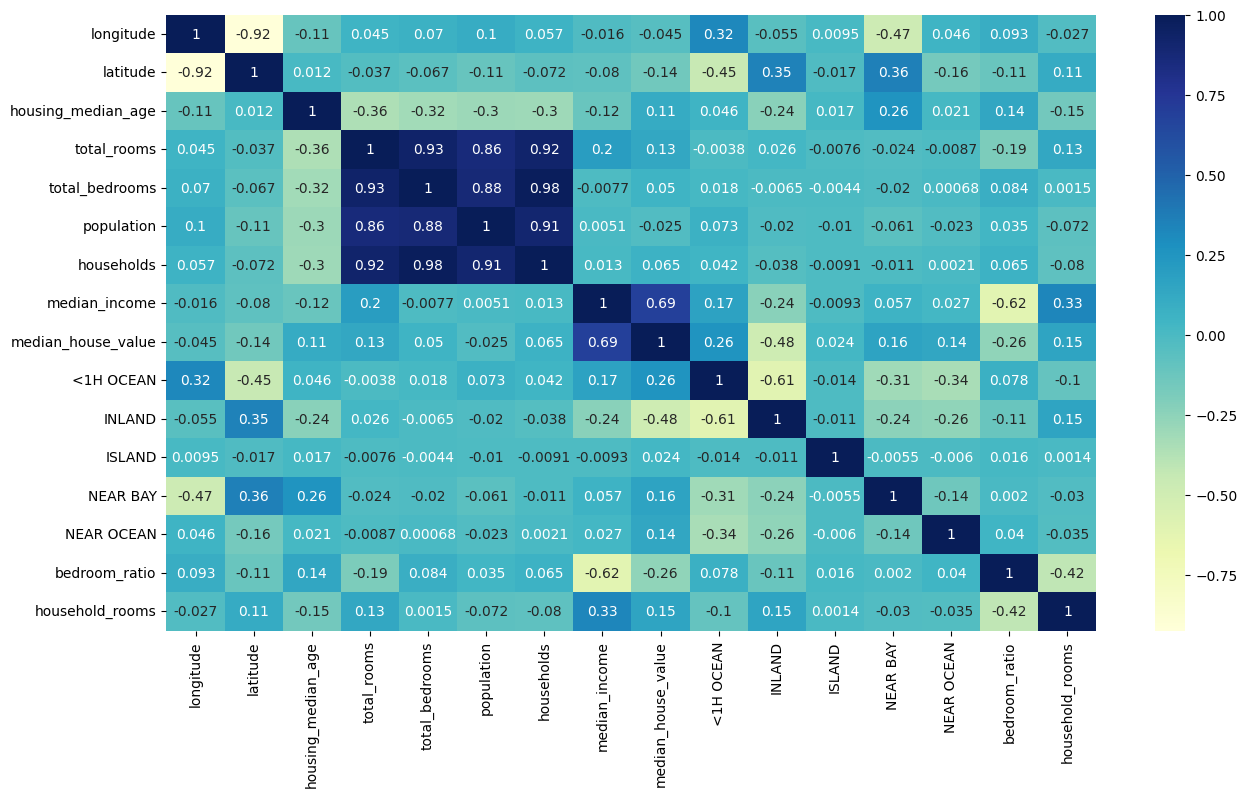

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="YlGnBu"
)
plt.show()

We can notice here that the new added features have higher correlations with the target variable.

* The ```bedroom_ratio``` has a negative correlation with the ```median_house_value```.
* The household in it self is not intresting, however the engineerd ```household_rooms``` feature has positve correlation with the ```median_house_value```

Sometimes, Dropping features that have very low correlation with the target can help in several ways:

* Reduce noise – Irrelevant features can confuse the model and reduce accuracy.
* Improve training speed – Fewer features → less computation.
* Prevent overfitting – Removing irrelevant features reduces the chance of fitting noise.

To list the least correlated features

In [ ]:
# Compute correlation of all features with the target column 'target'
correlation = df.corr()["median_house_value"].sort_values()

# Show low-correlation features
low_corr_features = correlation[abs(correlation) < 0.1].index
print(low_corr_features)

Index(['longitude', 'population', 'ISLAND', 'total_bedrooms', 'households'], dtype='object')


If you want to drop them, use the below command

In [ ]:
#df = df.drop(columns=low_corr_features)

# DEciding on the Features (X) and Target label (y)

In [ ]:
#Features only
X = df.drop(columns=["median_house_value"])

#Target Label is only the median_house_value feature
y = df["median_house_value"]

## Basic Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")

Training set size: 16346 samples
Test set size: 4087 samples
Training features shape: (16346, 15)
Test features shape: (4087, 15)


# Defining the ML Model

In [ ]:
from sklearn.linear_model import LinearRegression

linear_regressor_model= LinearRegression ()


### Fitting (Training) the Model

In [ ]:
linear_regressor_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
linear_regressor_model.score(X_test, y_test)

0.65138243084466

### Checking the performance of other Regressor (e.g., RandomForest)


In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor()

forest.fit(X_train, y_train)
forest.score(X_test, y_test)

0.8235161967023092

## Scaing Features
Feature scaling means transforming your numerical features to have a similar scale/range.

Imagine predicting house prices with these features:

* MedInc: 0-15 (median income)
* HouseAge: 0-52 (house age)
* AveRooms: 1-141 (average rooms)

Without scaling, features with larger numbers (like AveRooms) can dominate the model!



In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


In [ ]:
forest = RandomForestRegressor()

forest.fit(X_train_s, y_train)
forest.score(X_test_s, y_test)

0.8251631211897636

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],      # Number of trees
    'max_depth': [None,10, 20],          # How deep trees can grow
    'min_samples_split': [2, 5, 10],      # Minimum samples to split a node
}

model = RandomForestRegressor(random_state=42)

# Setup GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,                    # 5-fold cross validation
    scoring='neg_mean_squared_error',
    n_jobs=-1,               # Use all processors
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best score:", -grid_search.best_score_)  # Convert back from negative MS

Fitting 5 folds for each of 27 candidates, totalling 135 fits


KeyboardInterrupt: 

## Regression to Classification

In [ ]:
def value_to_class (value):
    _cls=0

    if value >= 400000:
        _cls=1
    elif value >=300000:
        _cls=2
    elif value >=200000:
        _cls=3
    elif value >=100000:
        _cls=4
    else:
        _cls=5

    return _cls


In [ ]:
#Test the Function First before applying to the Dataframe
value_to_class(382)

5

In [ ]:
df ["median_house_CLASS"] = df['median_house_value'].apply(value_to_class)

In [ ]:
df[["median_house_CLASS", "median_house_value"]]

,median_house_CLASS,median_house_value
0,1,452600.0
1,2,358500.0
2,2,352100.0
3,2,341300.0
4,2,342200.0
...,...,...
20635,5,78100.0
20636,5,77100.0
20637,5,92300.0
20638,5,84700.0


In [ ]:
X_new_cls = df.drop(['median_house_value', 'median_house_CLASS'], axis=1)  # Features (all columns except target)
y_new_cls = df['median_house_CLASS']

In [ ]:
# Check class distribution
print("Class distribution:")
print(y_new_cls.value_counts().sort_index())

Class distribution:
median_house_CLASS
1    1753
2    2077
3    4836
4    8213
5    3554
Name: count, dtype: int64


In [ ]:
# Split the data (80% train, 20% test)
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new_cls, y_new_cls,

    test_size=0.2,
    random_state=42,
)

print(f"Training set size: {X_train_new.shape[0]}")
print(f"Test set size: {X_test_new.shape[0]}")

Training set size: 16346
Test set size: 4087


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create and train Decision Tree
dt_classifier = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10
)

# Train the model
dt_classifier.fit(X_train_new, y_train_new)

# Make predictions
y_pred = dt_classifier.predict(X_test)


In [ ]:
# Evaluate performance of the Decision Tree
accuracy = accuracy_score(y_test_new, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.5980
